In [2]:
import os
import os.path as op

import matplotlib.pyplot as plt
import pickle

import pandas as pd
from hnn_core.hnn_io import write_network_configuration, read_network_configuration
from hnn_core.dipole import average_dipoles
from hnn_core.dipole import _rmse, average_dipoles

import sys

pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning'
sys.path.append(pth)
#
sys.path.append(op.join(pth, 'utils'))
from general_plot_utils import assign_color
import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = op.join(pth, 'new_model_HNN/figures/ERP_tuning_drives_conn')

# The number of cores may need modifying depending on your current machine.
n_procs = 10
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'

# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255



In [2]:
exp_dpl = read_dipole(op.join(pth, 'hnn-data/MEG_detection_data/S1_SupraT.txt'))

## Handtune

In [3]:
tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 5

In [76]:
from hnn_core import read_params

hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'default_human_ET_oct_version_nice_ERP.json')
params = read_params(params_fname)

In [77]:
synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}

In [78]:
net_seed544 = duecker_ET_model(params, add_drives_from_params=True)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    one_dpl = simulate_dipole(net_seed544, tstop=tstop, n_trials=1,bsl_cor='duecker')


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files

In [79]:
one_dpl[0].scale(scale_factor).smooth(smooth_window_len)

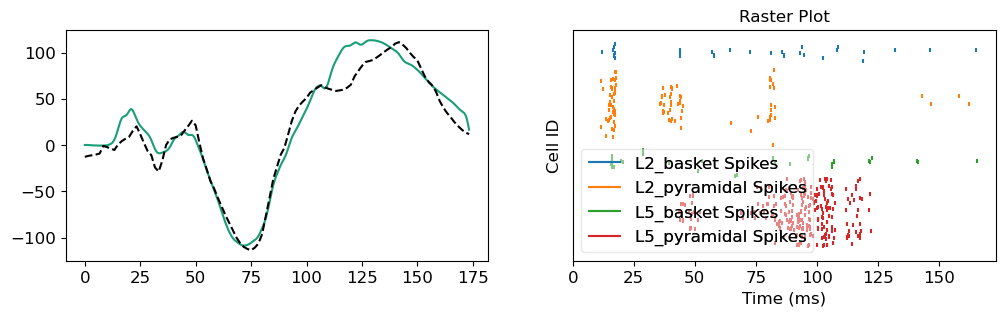

In [144]:
fig, ax = plt.subplots(1,2, figsize=(12, 3))

ax[0].plot(one_dpl[0].times, one_dpl[0].data['agg'], label='Seed 544', color=cols[0])

ax[0].plot(exp_dpl.times, exp_dpl.data['agg'], label='Experiment', color='k', linestyle='--')
net_seed544.cell_response.plot_spikes_raster(ax=ax[1])
fig.savefig(op.join(pathfig, 'ERP_seed544_vs_exp.png'), dpi=300, bbox_inches='tight')

In [135]:
net_multi = duecker_ET_model(params, add_drives_from_params=True)


In [139]:
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    multi_dpl = simulate_dipole(net_multi, tstop=tstop, n_trials=10,bsl_cor='duecker')

MPI will run 10 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loa

In [141]:
multi_dpl = [dpl.scale(scale_factor).smooth(smooth_window_len) for dpl in multi_dpl]

In [138]:
prox1_spikes = net_multi.cell_response.spike_times_by_type['evprox1']

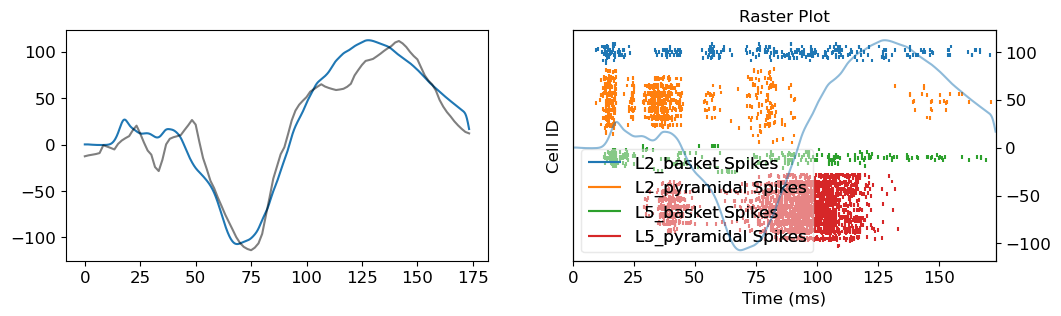

In [143]:
avg_dpl = average_dipoles(multi_dpl)
fig, ax = plt.subplots(1,2,figsize=(12,3))
ax[0].plot(avg_dpl.times, avg_dpl.data['agg'], label='10 trials')
ax[0].plot(exp_dpl.times, exp_dpl.data['agg'], label='Experiment', color='k', alpha=0.5)
net_multi.cell_response.plot_spikes_raster(ax=ax[1], show=False)
axtw = ax[1].twinx()
axtw.plot(avg_dpl.times, avg_dpl.data['agg'], alpha=0.5)
fig.savefig(op.join(pathfig, 'ERP_multi10.png'), dpi=300, bbox_inches='tight')

In [86]:
from scipy.signal import find_peaks
pk = find_peaks(exp_dpl.data['agg'], height=0)
exp_dpl.times[pk[0]]

array([ 23.33333333,  48.33333333, 106.66666667, 141.66666667])

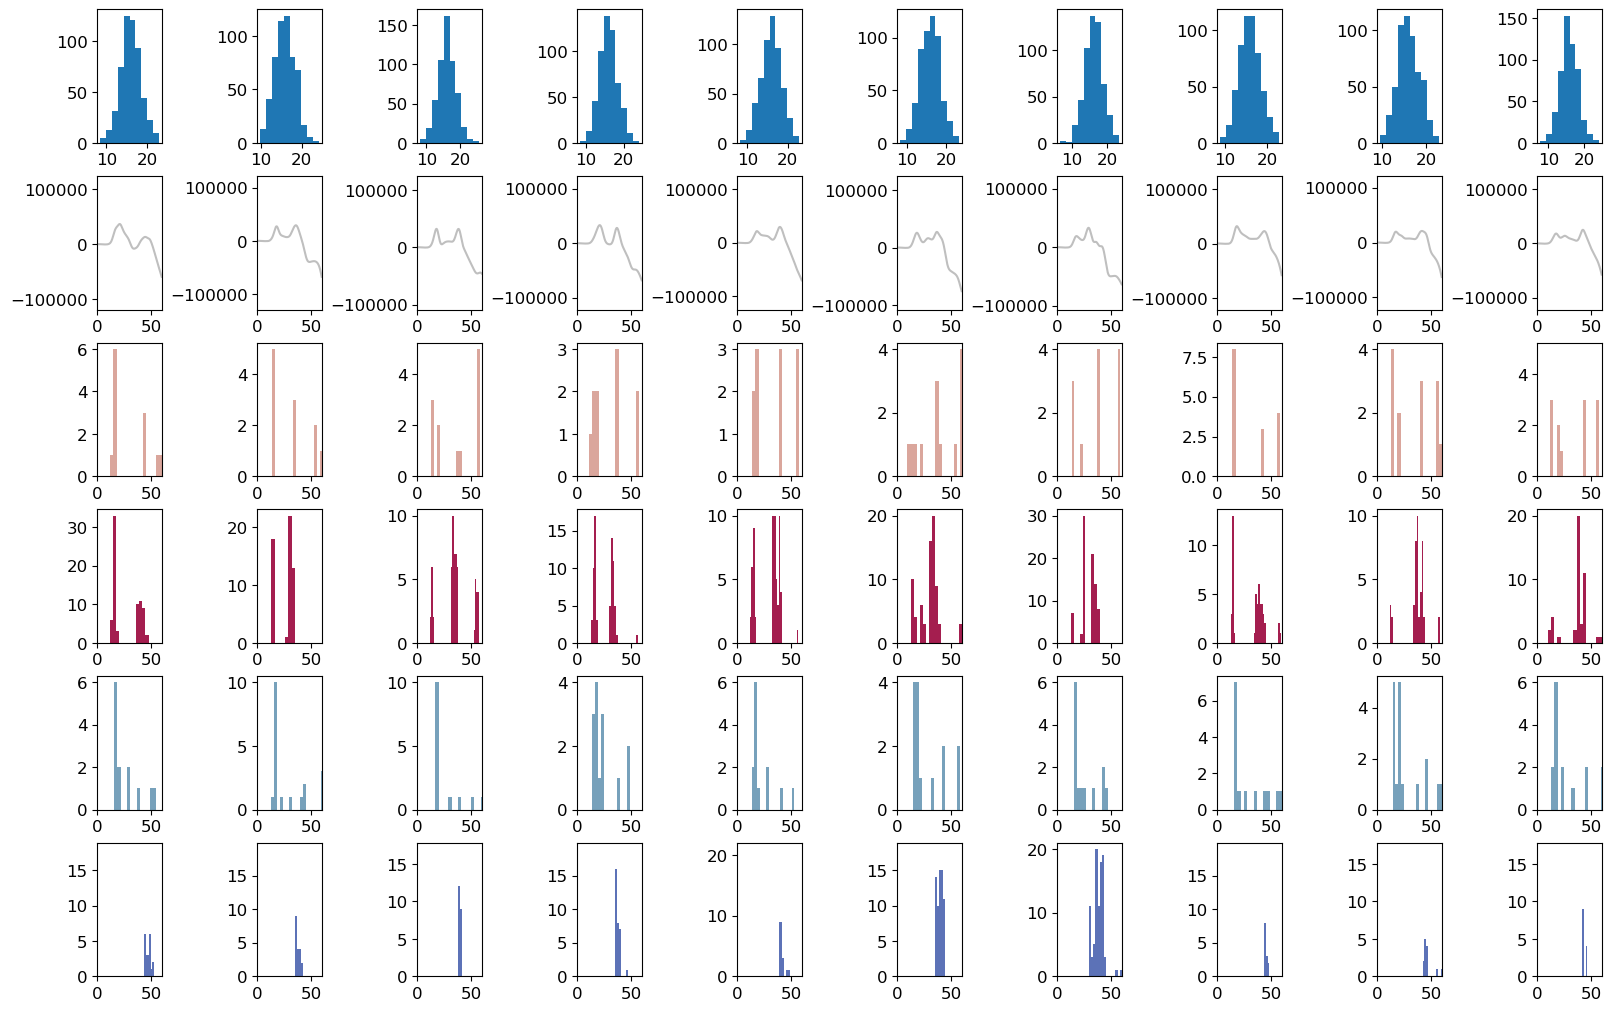

In [87]:
fig, ax = plt.subplots(6,10,figsize=(16,10), constrained_layout=True)
for i in range(10):
    ax[0,i].hist(net_multi.cell_response.spike_times_by_type['evprox1'][i])
    ax[1,i].plot(multi_dpl[i].times, multi_dpl[i].data['agg'], color='gray', alpha=0.5)
    
    ax[2,i].hist(net_multi.cell_response.spike_times_by_type['L2_basket'][i], color=cm_neurons[0], bins=50)
    ax[3,i].hist(net_multi.cell_response.spike_times_by_type['L2_pyramidal'][i], color=cm_neurons[1], bins=50)
    ax[4,i].hist(net_multi.cell_response.spike_times_by_type['L5_basket'][i], color=cm_neurons[2], bins=50)
    ax[5,i].hist(net_multi.cell_response.spike_times_by_type['L5_pyramidal'][i], color=cm_neurons[3], bins=50)
    for a in np.arange(1,6):
        ax[a,i].set_xlim(0, 60)

fig.savefig(op.join(pathfig, 'ERP_ET_seed_compare_spikes.png'))


In [88]:
# The goal of the below is to find out if the timing of the drive cell spiking is really different across trials due to the gaussian drive

In [89]:
from hnn_core.network import pick_connection
from hnn_core.viz import plot_drive_strength, plot_connectivity_matrix
from hnn_core.cell import _get_gaussian_connection

# pick connection
conn_idx_l23 = pick_connection(net_multi, src_gids='evprox1', target_gids='L2_pyramidal')
conn_idx_l23int = pick_connection(net_multi, src_gids='evprox1', target_gids='L2_basket')

# get GIDs of sources
src_range = np.array(net_multi.gid_ranges["evprox1"])

# color gids based on cell type
gids = range(0, 270)
colors = [assign_color(net_multi, gid) for gid in gids]

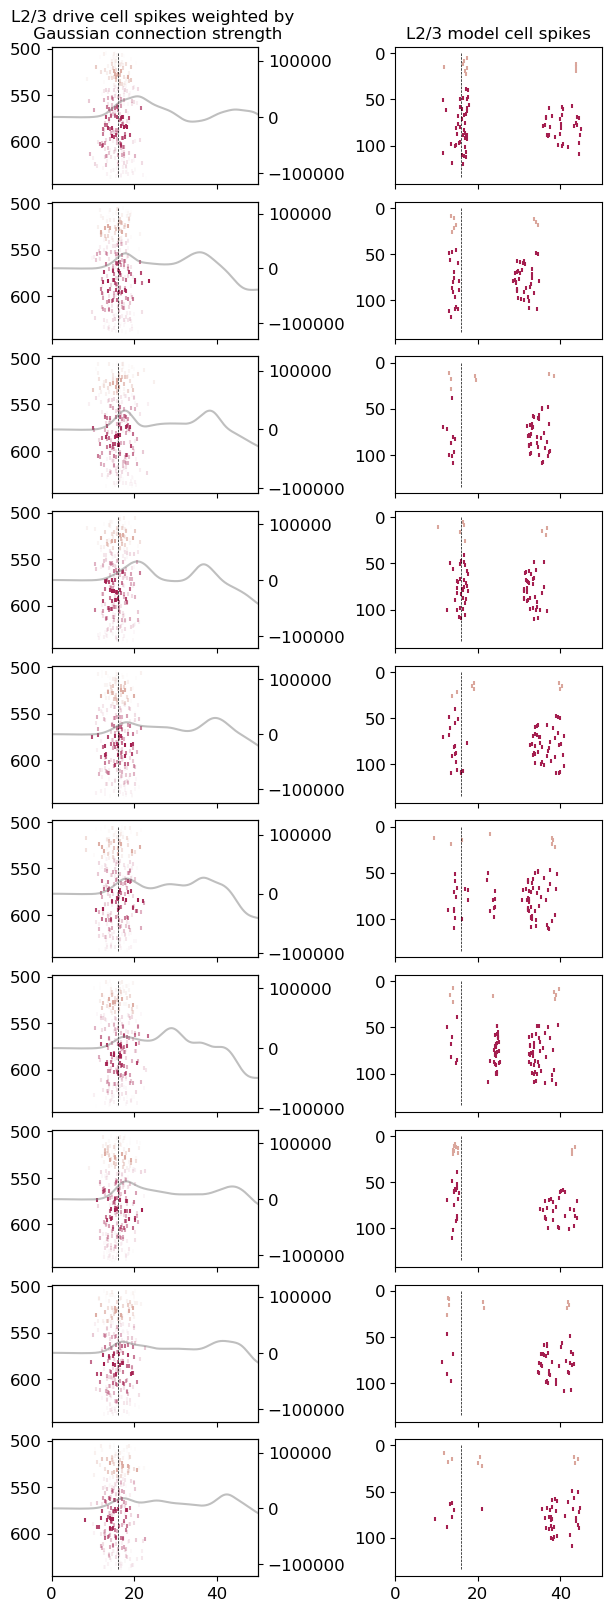

In [90]:
# get the L2/3 drive gids and respective target gids

l23_drive_gids = np.array(list(net_multi.connectivity[conn_idx_l23[0]]['src_gids']))
l23_target_gids = np.array(list(net_multi.connectivity[conn_idx_l23[0]]['target_gids']))
l23_int_drive_gids = np.array(list(net_multi.connectivity[conn_idx_l23int[0]]['src_gids']))
l23_int_target_gids = np.array(list(net_multi.connectivity[conn_idx_l23int[0]]['target_gids']))

fig, ax = plt.subplots(10,2,figsize=(6,16), constrained_layout=True, sharex=True)

# loop over trials
for t in range(10):
    # get spike gids and times
    spike_gids = np.array(net_multi.cell_response.spike_gids[t])
    l23_spike_gids = spike_gids[(spike_gids >= 35) & (spike_gids <= 134)]
    l23_int_spike_gids = spike_gids[(spike_gids >= 0) & (spike_gids <= 34)]
    spike_times = np.array(net_multi.cell_response.spike_times[t])
    l23_spike_times = spike_times[(spike_gids >= 35) & (spike_gids <= 134)]
    l23_int_spike_times = spike_times[(spike_gids >= 0) & (spike_gids <= 34)]
    ax[t,0].vlines(16, np.min(l23_int_drive_gids), np.max(l23_drive_gids), color='k', linestyle='--',linewidth=0.5)
    ax[t,1].vlines(16, 0, 135, color='k', linestyle='--',linewidth=0.5)

    for si, sg in enumerate(spike_gids):
        if (sg == l23_drive_gids).any():
            idx = np.where(sg == l23_drive_gids)[0][0]
            pos_idx = np.where(src_range == l23_drive_gids[idx])[0][0]
            src_pos = net_multi.pos_dict['evprox1'][pos_idx]
            target_pos = net_multi.pos_dict['L2_pyramidal'][np.where(l23_target_gids[idx] == net_multi.gid_ranges['L2_pyramidal'])[0][0]]
            nc_dict = net_multi.connectivity[conn_idx_l23[0]]["nc_dict"]
            weight, _ = _get_gaussian_connection(src_pos, target_pos, nc_dict)
            # plot firing based on gaussian weight
            ax[t,0].scatter(spike_times[si], sg, s=10, color=colors[l23_target_gids[idx]], marker='|', alpha=weight/net_multi.connectivity[conn_idx_l23[0]]['nc_dict']['A_weight'])
        if (sg == l23_int_drive_gids).any():
            idx = np.where(sg == l23_int_drive_gids)[0][0]
            pos_idx = np.where(src_range == l23_int_drive_gids[idx])[0][0]
            src_pos = net_multi.pos_dict['evprox1'][pos_idx]
            target_pos = net_multi.pos_dict['L2_basket'][np.where(l23_int_target_gids[idx] == net_multi.gid_ranges['L2_basket'])[0][0]]
            nc_dict = net_multi.connectivity[conn_idx_l23int[0]]["nc_dict"]
            weight, _ = _get_gaussian_connection(src_pos, target_pos, nc_dict)
            # plot firing based on gaussian weight
            ax[t,0].scatter(spike_times[si], sg, s=10, color=colors[l23_int_target_gids[idx]], marker='|', alpha=weight/net_multi.connectivity[conn_idx_l23int[0]]['nc_dict']['A_weight'])
    ax[t,0].invert_yaxis()
    ax[t,1].scatter(l23_spike_times, l23_spike_gids, s=10, color=cm_neurons[1], marker='|')
    ax[t,1].scatter(l23_int_spike_times, l23_int_spike_gids, s=10, color=cm_neurons[0], marker='|')


    ax[t,1].invert_yaxis()
    axtw = ax[t,0].twinx()
    axtw.plot(multi_dpl[t].times, multi_dpl[t].data['agg'], color='gray', alpha=0.5)
    axtw.set_xlim(0, 50)

ax[0,0].set_title('L2/3 drive cell spikes weighted by \n Gaussian connection strength')
ax[0,1].set_title('L2/3 model cell spikes')
fig.savefig(op.join(pathfig, 'ERP_ET_seed_compare_spikes_gaussian_weight.png'))

In [98]:
pos_idx = np.where(src_range == l23_drive_gids[0])[0][0]
pos_idx

np.int64(35)

In [121]:
int(target_pos[0])

7

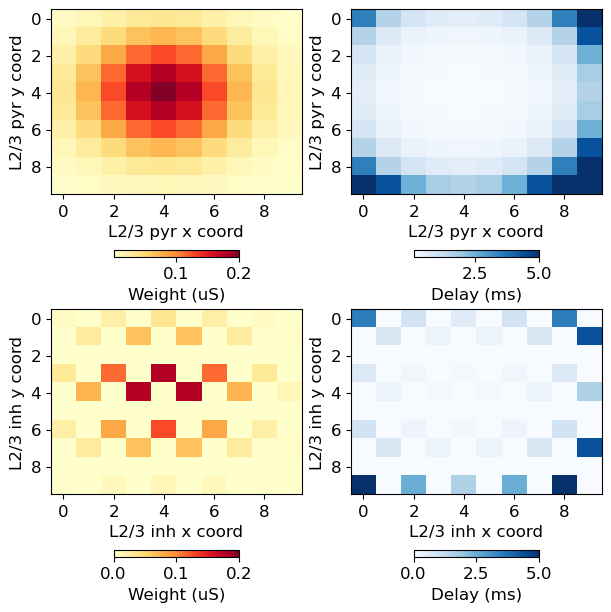

In [ ]:
# weight and space constant between dirve cells and L2 pyramidal cells
l23_drive_gids = np.array(list(net_multi.connectivity[conn_idx_l23[0]]['src_gids']))
l23_target_gids = np.array(list(net_multi.connectivity[conn_idx_l23[0]]['target_gids']))
l23_int_drive_gids = np.array(list(net_multi.connectivity[conn_idx_l23int[0]]['src_gids']))
l23_int_target_gids = np.array(list(net_multi.connectivity[conn_idx_l23int[0]]['target_gids']))
t = 0

weights_l23 = np.zeros((10, 10))
delay_l23 = np.zeros((10, 10))
for spi, sg in enumerate(l23_drive_gids):
    src_pos_idx = np.where(src_range == sg)[0][0]
    src_pos = net_multi.pos_dict["evprox1"][src_pos_idx]
    target_pos = net_multi.pos_dict["L2_pyramidal"][spi] 
    nc_dict = net_multi.connectivity[conn_idx_l23[0]]["nc_dict"]
    weight, delay = _get_gaussian_connection(src_pos, target_pos, nc_dict)
    weights_l23[int(target_pos[0]), int(target_pos[1])] = weight
    delay_l23[int(target_pos[0]), int(target_pos[1])] = delay

weights_l23_int = np.zeros((10, 10))
delay_l23_int = np.zeros((10, 10))
for spi, sg in enumerate(l23_int_drive_gids):
    src_pos_idx = np.where(src_range == sg)[0][0]
    src_pos = net_multi.pos_dict["evprox1"][src_pos_idx]
    target_pos = net_multi.pos_dict["L2_basket"][spi]   
    nc_dict = net_multi.connectivity[conn_idx_l23int[0]]["nc_dict"]
    weight, delay = _get_gaussian_connection(src_pos, target_pos, nc_dict)
    weights_l23_int[int(target_pos[0]), int(target_pos[1])] = weight
    delay_l23_int[int(target_pos[0]), int(target_pos[1])] = delay

fig, ax = plt.subplots(2,2, figsize=(6,6), constrained_layout=True)
ax = ax.ravel()
im = ax[0].imshow(weights_l23, aspect='auto', cmap='YlOrRd', vmax=0.2)
ax[0].set_ylabel('L2/3 pyr y coord')
ax[0].set_xlabel('L2/3 pyr x coord')
cb = plt.colorbar(im, ax=ax[0], orientation='horizontal', shrink=0.5)
cb.ax.set_xlabel('Weight (uS)')
im = ax[1].imshow(delay_l23, aspect='auto', cmap='Blues', vmax=5)
ax[1].set_ylabel('L2/3 pyr y coord')
ax[1].set_xlabel('L2/3 pyr x coord')
cb = plt.colorbar(im, ax=ax[1], orientation='horizontal', shrink=0.5)
cb.ax.set_xlabel('Delay (ms)')

im = ax[2].imshow(weights_l23_int, aspect='auto', cmap='YlOrRd', vmax=0.2)
ax[2].set_ylabel('L2/3 inh y coord')
ax[2].set_xlabel('L2/3 inh x coord')
cb = plt.colorbar(im, ax=ax[2], orientation='horizontal', shrink=0.5)
cb.ax.set_xlabel('Weight (uS)') 
im = ax[3].imshow(delay_l23_int, aspect='auto', cmap='Blues', vmax=5)
ax[3].set_ylabel('L2/3 inh y coord')
ax[3].set_xlabel('L2/3 inh x coord')
cb = plt.colorbar(im, ax=ax[3], orientation='horizontal', shrink=0.5)
cb.ax.set_xlabel('Delay (ms)')

fig.savefig(op.join(pathfig, 'L23_weight_delay_matrix.png'))

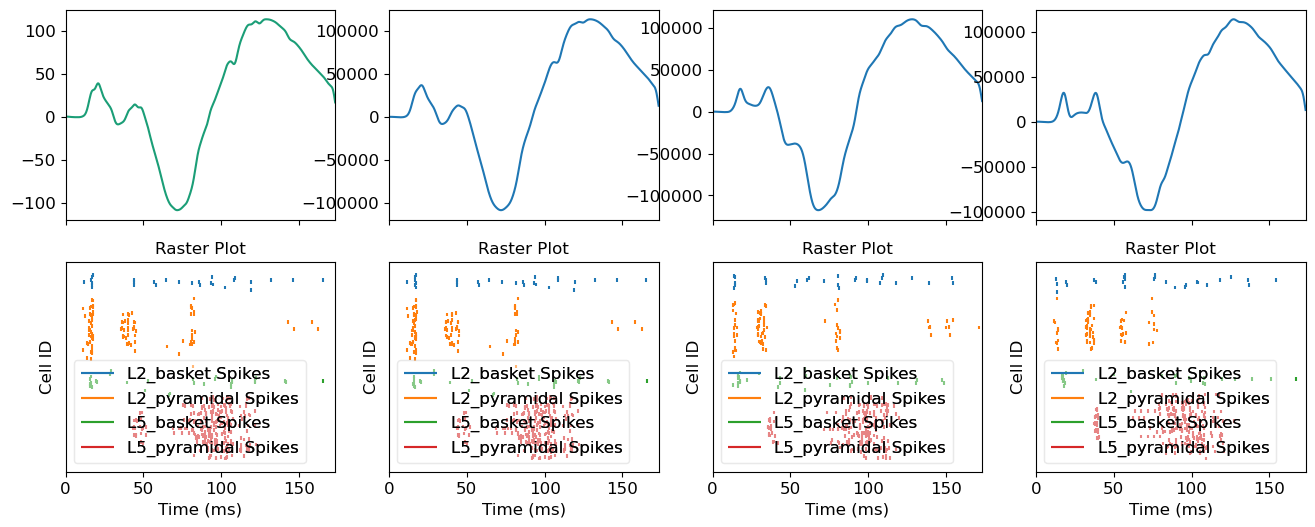

In [19]:
fig, ax = plt.subplots(2,4,figsize=(16,6), sharex=True)
ax[0,0].plot(one_dpl[0].times, one_dpl[0].data['agg'], color=cols[0], label='Seed 544 - 1 trial')
net_seed544.cell_response.plot_spikes_raster(ax=ax[1,0], show=False)
for i in range(3):
    ax[0,1+i].plot(multi_dpl[i].times, multi_dpl[i].data['agg'])
    net_multi.cell_response.plot_spikes_raster(trial_idx=i, ax=ax[1,1+i], show=False)

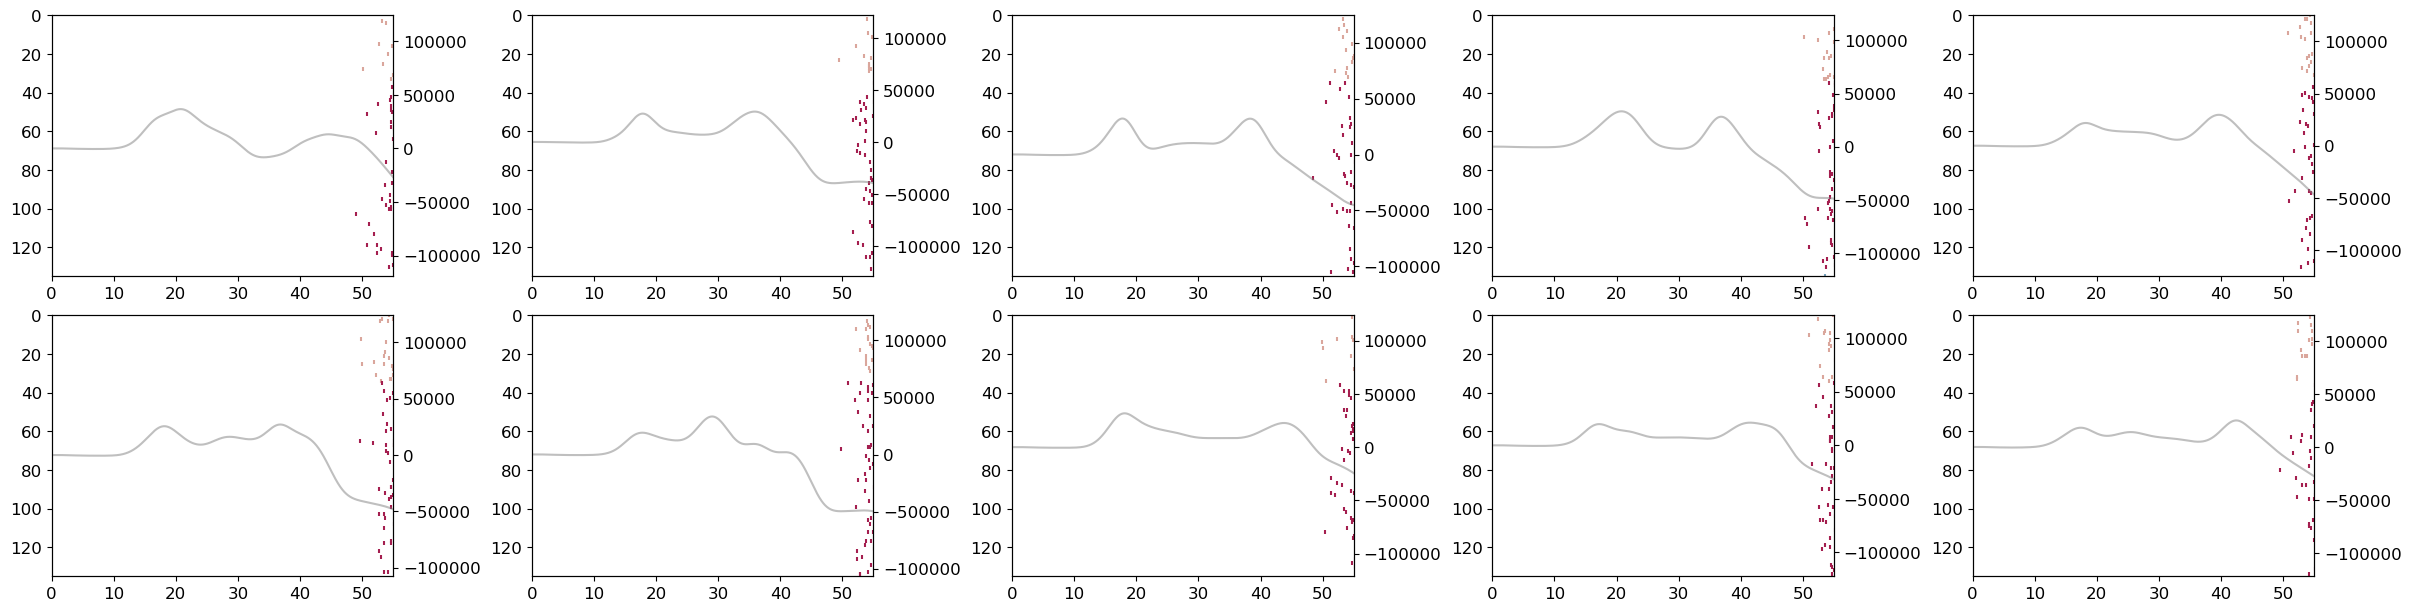

In [20]:
fig, ax = plt.subplots(2,5,figsize=(24,6), constrained_layout=True)
ax = ax.flatten()
for t in range(10):
    spike_gids = np.array(net_multi.cell_response.spike_gids[t])-270
    spike_times = np.array(net_multi.cell_response.spike_times[t])

    # first drive: the first 270 gids
    spike_times = spike_times[(spike_gids>=0) & (spike_gids<=270)]
    spike_gids = spike_gids[(spike_gids>=0) & (spike_gids<=270)]
    colors = [assign_color(net_multi, gid) for gid in spike_gids]
    for ic, c in enumerate(colors):
        ax[t].scatter(spike_times[ic], spike_gids[ic], s=10, color=c, marker='|')
    ax[t].set_ylim([0, 135])
    ax[t].invert_yaxis()
    axtw = ax[t].twinx()
    axtw.plot(multi_dpl[t].times, multi_dpl[t].data['agg'], color='gray', alpha=0.5)
    axtw.set_xlim(0,55)

fig.savefig(op.join(pathfig, 'drive_cells_coloring.png'))


In [145]:
params_fname = op.join(hnn_core_root, 'param', 'human_ET_wider_lamtha.json')
params = read_params(params_fname)

net_seed544 = duecker_ET_model(params, add_drives_from_params=False)

prox1_weights_ampa = {'L2_basket': 0.015141233246900306*0.1,
 'L2_pyramidal': 0.19829979134577552*0.5,
 'L5_basket': 0.09982007572608793,
 'L5_pyramidal': 0.0021341968074163583}
prox1_weights_nmda = {'L2_basket': 0.0002063272798741935*0.1,
 'L2_pyramidal': 0.07251788470713583,
 'L5_basket': 0.0036571714922861353,
 'L5_pyramidal': 0.0012865471093500263}
synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
net_seed544.add_evoked_drive('evprox1',
                        mu=25.5,
                        sigma=7,
                        numspikes=6,
                        location='proximal',
                        weights_ampa=prox1_weights_ampa,
                        weights_nmda=prox1_weights_nmda,
                        synaptic_delays=synaptic_delays_p, n_drive_cells = 1, cell_specific=False, event_seed=544)

# Distal
synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}


dist_weights_ampa = {'L2_basket': 0.007286703490725222,
 'L2_pyramidal':  0.09676106407799837,
 'L5_pyramidal': 0.6477491727291692}
dist_weights_nmda = {'L2_basket': 0.00015031590629803124,
 'L2_pyramidal': 0.016378815180046424,
 'L5_pyramidal': 0.9825781393257241}
net_seed544.add_evoked_drive('evdist',
                        mu=58.976201512904886,
                        sigma=2.968601372132023,
                        numspikes=5,
                        location='distal',
                        weights_ampa=dist_weights_ampa,
                        weights_nmda=dist_weights_nmda,
                        synaptic_delays=synaptic_delays_d, event_seed=544)

# proximal 2
prox2_weights_ampa = {'L2_basket': 0.008854002662882252,
 'L2_pyramidal': 0.8055424136672362,
 'L5_basket': 0.0060532072706363646,
 'L5_pyramidal': 0.36592529786870476}
prox2_weights_nmda = {'L2_basket': 0.005633312240650203,
 'L2_pyramidal': 0.12954220939424865,
 'L5_basket': 0.0028826041050047696,
 'L5_pyramidal': 0.34406261148667705}
net_seed544.add_evoked_drive('evprox2',
                    mu=100, #94.89656277244218,
                    sigma=11.322646413432793,
                    numspikes=6,
                    location='proximal',
                    weights_ampa=prox2_weights_ampa,
                    weights_nmda=prox2_weights_nmda,
                    synaptic_delays=synaptic_delays_p, event_seed=544)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    one_dpl = simulate_dipole(net_seed544, tstop=tstop, n_trials=1,bsl_cor='duecker')

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

In [146]:
one_dpl[0].scale(scale_factor).smooth(smooth_window_len)

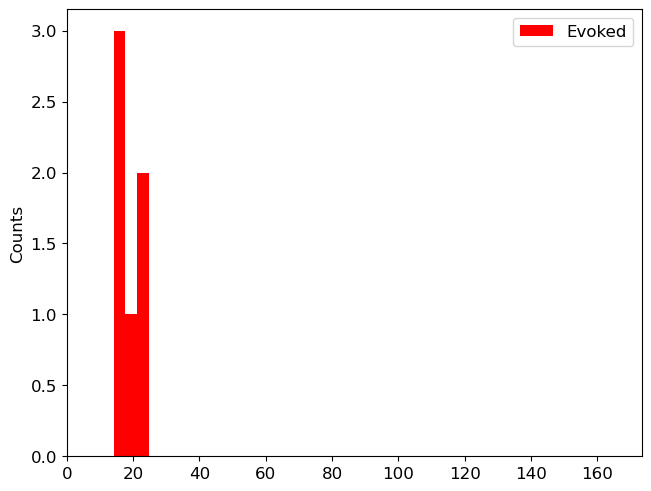

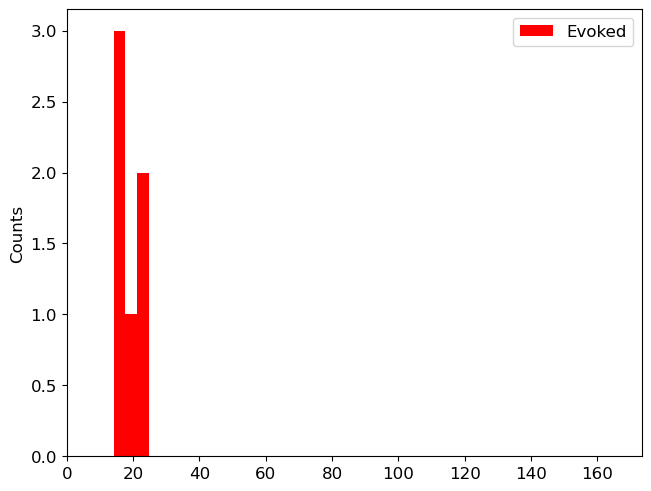

In [149]:
net_seed544.cell_response.plot_spikes_hist(show=False, spike_types={'Evoked': ['evprox1']})

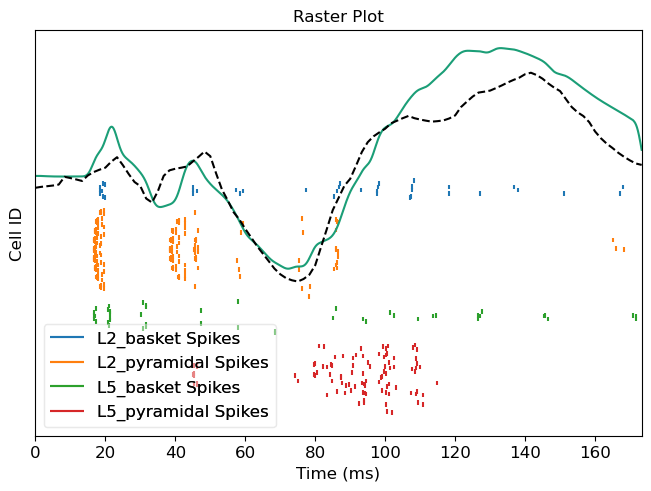

In [152]:
net_seed544.cell_response.plot_spikes_raster(show=False)
plt.plot(one_dpl[0].times, one_dpl[0].data['agg'], label='Seed 544', color=cols[0])

plt.plot(exp_dpl.times, exp_dpl.data['agg'], label='Experiment', color='k', linestyle='--')

In [153]:

net_multi = duecker_ET_model(params, add_drives_from_params=False)
net_multi.add_evoked_drive('evprox1',
                        mu=25.5,
                        sigma=7,
                        numspikes=1,
                        location='proximal',
                        weights_ampa=prox1_weights_ampa,
                        weights_nmda=prox1_weights_nmda,
                        synaptic_delays=synaptic_delays_p, n_drive_cells = 1, cell_specific=False, event_seed=544)
# net_multi.add_evoked_drive('evdist',
#                         mu=58.976201512904886,
#                         sigma=2.968601372132023,
#                         numspikes=5,
#                         location='distal',
#                         weights_ampa=dist_weights_ampa,
#                         weights_nmda=dist_weights_nmda,
#                         synaptic_delays=synaptic_delays_d, event_seed=544)

# net_multi.add_evoked_drive('evprox2',
#                     mu=100, #94.89656277244218,
#                     sigma=11.322646413432793,
#                     numspikes=6,
#                     location='proximal',
#                     weights_ampa=prox2_weights_ampa,
#                     weights_nmda=prox2_weights_nmda,
#                     synaptic_delays=synaptic_delays_p, event_seed=544)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    multi_dpl = simulate_dipole(net_multi, tstop=tstop, n_trials=10,bsl_cor='duecker')


MPI will run 10 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loa

In [158]:
l23_int_target_gids

array([170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182,
       183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195,
       196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208,
       209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221,
       222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234,
       235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247,
       248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260,
       261, 262, 263, 264, 265, 266, 267, 268, 269])

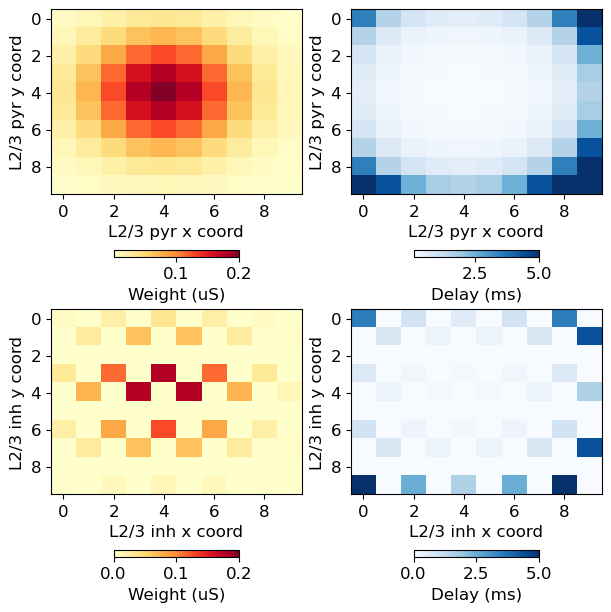

In [159]:
# weight and space constant between dirve cells and L2 pyramidal cells
# pick connection
conn_idx_l23 = pick_connection(net_multi, src_gids='evprox1', target_gids='L2_pyramidal')
conn_idx_l23int = pick_connection(net_multi, src_gids='evprox1', target_gids='L2_basket')

# get GIDs of sources
src_range = np.array(net_multi.gid_ranges["evprox1"])

l23_drive_gids = np.array(list(net_multi.connectivity[conn_idx_l23[0]]['src_gids']))
l23_target_gids = np.array(list(net_multi.connectivity[conn_idx_l23[0]]['target_gids']))
l23_int_drive_gids = np.array(list(net_multi.connectivity[conn_idx_l23int[0]]['src_gids']))
l23_int_target_gids = np.array(list(net_multi.connectivity[conn_idx_l23int[0]]['target_gids']))
t = 0
src_range = np.array(net_multi.gid_ranges["evprox1"])

weights_l23 = np.zeros((10, 10))
delay_l23 = np.zeros((10, 10))
for spi, sg in enumerate(l23_target_gids):
    src_pos = net_multi.pos_dict["evprox1"][0]
    target_pos = net_multi.pos_dict["L2_pyramidal"][spi] 

    weight, delay = _get_gaussian_connection(src_pos, target_pos, nc_dict)
    weights_l23[int(target_pos[0]), int(target_pos[1])] = weight
    delay_l23[int(target_pos[0]), int(target_pos[1])] = delay

weights_l23_int = np.zeros((10, 10))
delay_l23_int = np.zeros((10, 10))
for spi, sg in enumerate(l23_int_target_gids):
    src_pos = net_multi.pos_dict["evprox1"][0]
    target_pos = net_multi.pos_dict["L2_basket"][spi]   

    weight, delay = _get_gaussian_connection(src_pos, target_pos, nc_dict)
    weights_l23_int[int(target_pos[0]), int(target_pos[1])] = weight
    delay_l23_int[int(target_pos[0]), int(target_pos[1])] = delay

fig, ax = plt.subplots(2,2, figsize=(6,6), constrained_layout=True)
ax = ax.ravel()
im = ax[0].imshow(weights_l23, aspect='auto', cmap='YlOrRd', vmax=0.2)
ax[0].set_ylabel('L2/3 pyr y coord')
ax[0].set_xlabel('L2/3 pyr x coord')
cb = plt.colorbar(im, ax=ax[0], orientation='horizontal', shrink=0.5)
cb.ax.set_xlabel('Weight (uS)')
im = ax[1].imshow(delay_l23, aspect='auto', cmap='Blues', vmax=5)
ax[1].set_ylabel('L2/3 pyr y coord')
ax[1].set_xlabel('L2/3 pyr x coord')
cb = plt.colorbar(im, ax=ax[1], orientation='horizontal', shrink=0.5)
cb.ax.set_xlabel('Delay (ms)')

im = ax[2].imshow(weights_l23_int, aspect='auto', cmap='YlOrRd', vmax=0.2)
ax[2].set_ylabel('L2/3 inh y coord')
ax[2].set_xlabel('L2/3 inh x coord')
cb = plt.colorbar(im, ax=ax[2], orientation='horizontal', shrink=0.5)
cb.ax.set_xlabel('Weight (uS)') 
im = ax[3].imshow(delay_l23_int, aspect='auto', cmap='Blues', vmax=5)
ax[3].set_ylabel('L2/3 inh y coord')
ax[3].set_xlabel('L2/3 inh x coord')
cb = plt.colorbar(im, ax=ax[3], orientation='horizontal', shrink=0.5)
cb.ax.set_xlabel('Delay (ms)')

fig.savefig(op.join(pathfig, 'L23_weight_delay_matrix_one_drive.png'))

In [73]:
multi_dpl = [dpl.scale(scale_factor).smooth(smooth_window_len) for dpl in multi_dpl]


In [74]:
bins = np.arange(0, tstop, 5)  # histogram bins

spike_prox1 = np.array(net_multi.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net_multi.cell_response.spike_times_by_type['evdist']).reshape(-1,1)
spike_prox2 = np.array(net_multi.cell_response.spike_times_by_type['evprox2']).reshape(-1,1)




KeyError: 'evdist'

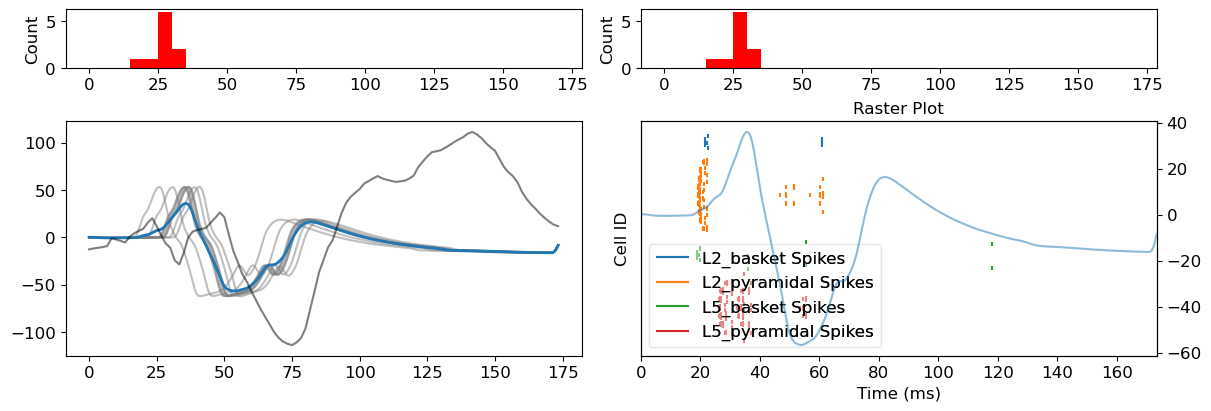

In [75]:
avg_dpl = average_dipoles(multi_dpl)
fig, ax = plt.subplots(2,2,figsize=(12,4), height_ratios=[0.25,1], constrained_layout=True)

for i in range(2):
    ax[0, i].hist(spike_prox1, bins, color='r')
    # ax[0, i].set_ylim([0, 1000])
    ax[0, i].set_ylabel('Count')
    # ax[0, i].hist(spike_prox2, bins, color='r')

    # ax1tw = ax[0, i].twinx()
    # ax1tw.hist(spike_dist, bins, color='g')
    # ax1tw.set_ylim([0, 1000])
    # ax1tw.invert_yaxis()

for dpl in multi_dpl:
    ax[1,0].plot(dpl.times, dpl.data['agg'], color='gray', alpha=0.5)
ax[1,0].plot(avg_dpl.times, avg_dpl.data['agg'], label='10 trials', linewidth=2)

ax[1,0].plot(exp_dpl.times, exp_dpl.data['agg'], label='Experiment', color='k', alpha=0.5)
net_multi.cell_response.plot_spikes_raster(trial_idx=0, ax=ax[1,1], show=False)
axtw = ax[1,1].twinx()
axtw.plot(avg_dpl.times, avg_dpl.data['agg'], alpha=0.5)
fig.savefig(op.join(pathfig, 'erp_prox_1_cell.png'))


In [61]:
_get_gaussian_connection(src_pos, (np.float64(4.0), np.float64(4.0), 1307.4), nc_dict)

(np.float64(0.09914989567288776), np.float64(0.1))

In [58]:
src_pos

(np.float64(4.0), np.float64(4.0), np.float64(653.0))

In [59]:
net_multi.pos_dict['L2_pyramidal']

[(np.float64(0.0), np.float64(0.0), 1307.4),
 (np.float64(0.0), np.float64(1.0), 1307.4),
 (np.float64(0.0), np.float64(2.0), 1307.4),
 (np.float64(0.0), np.float64(3.0), 1307.4),
 (np.float64(0.0), np.float64(4.0), 1307.4),
 (np.float64(0.0), np.float64(5.0), 1307.4),
 (np.float64(0.0), np.float64(6.0), 1307.4),
 (np.float64(0.0), np.float64(7.0), 1307.4),
 (np.float64(0.0), np.float64(8.0), 1307.4),
 (np.float64(0.0), np.float64(9.0), 1307.4),
 (np.float64(1.0), np.float64(0.0), 1307.4),
 (np.float64(1.0), np.float64(1.0), 1307.4),
 (np.float64(1.0), np.float64(2.0), 1307.4),
 (np.float64(1.0), np.float64(3.0), 1307.4),
 (np.float64(1.0), np.float64(4.0), 1307.4),
 (np.float64(1.0), np.float64(5.0), 1307.4),
 (np.float64(1.0), np.float64(6.0), 1307.4),
 (np.float64(1.0), np.float64(7.0), 1307.4),
 (np.float64(1.0), np.float64(8.0), 1307.4),
 (np.float64(1.0), np.float64(9.0), 1307.4),
 (np.float64(2.0), np.float64(0.0), 1307.4),
 (np.float64(2.0), np.float64(1.0), 1307.4),
 (np.float

In [63]:
pos_idx = np.where(src_range == l23_drive_gids[0])[0][0]
pos_idx

np.int64(0)

0.002832266422631961
0.0061647958700956325
0.010744678196728048
0.014995406394905271
0.016757652589840327
0.014995406394905271
0.010744678196728048
0.0061647958700956325
0.002832266422631961
0.002832266422631961
0.0061647958700956325
0.010744678196728048
0.014995406394905271
0.016757652589840327
0.014995406394905271
0.010744678196728048
0.002832266422631961
0.0061647958700956325
0.010744678196728048
0.002267901659626797
0.016757652589840327
0.014995406394905271
0.04076174071362955
0.05688759180807893
0.06357296862033165
0.05688759180807893
0.04076174071362955
0.02338718816965725
0.010744678196728048
0.003952746210579298
0.014995406394905271
0.04076174071362955
0.05688759180807893
0.06357296862033165
0.05688759180807893
0.04076174071362955
0.02338718816965725
0.010744678196728048
0.04076174071362955
0.06357296862033165
0.04076174071362955
0.05688759180807893
0.02338718816965725
0.06357296862033165
0.04076174071362955
0.014995406394905271
0.05688759180807893
0.04076174071362955
0.0167576

IndexError: index 106 is out of bounds for axis 0 with size 100

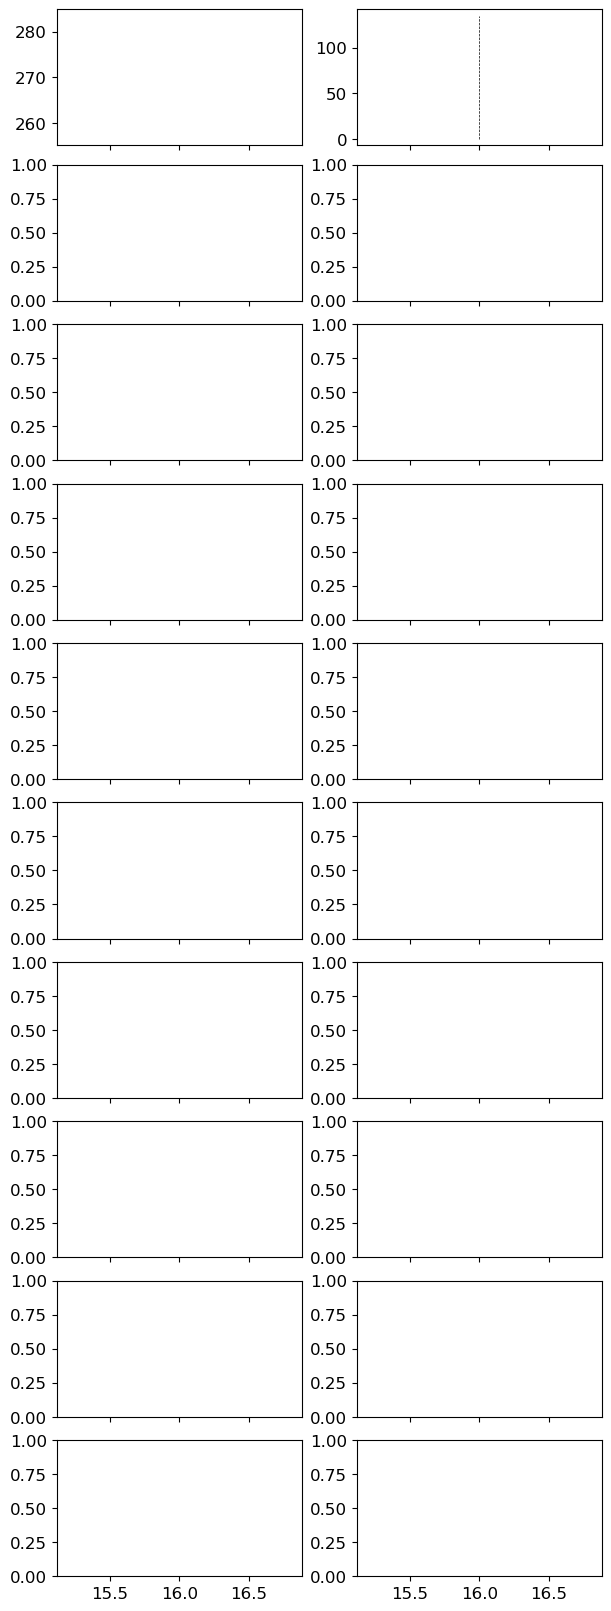

In [64]:
# pick connection
conn_idx_l23 = pick_connection(net_multi, src_gids='evprox1', target_gids='L2_pyramidal')
conn_idx_l23int = pick_connection(net_multi, src_gids='evprox1', target_gids='L2_basket')

# get GIDs of sources
src_range = np.array(net_multi.gid_ranges["evprox1"])

# color gids based on cell type
gids = range(0, 270)
colors = [assign_color(net_multi, gid) for gid in gids]


l23_drive_gids = np.array(list(net_multi.connectivity[conn_idx_l23[0]]['src_gids']))
l23_target_gids = np.array(list(net_multi.connectivity[conn_idx_l23[0]]['target_gids']))
l23_int_drive_gids = np.array(list(net_multi.connectivity[conn_idx_l23int[0]]['src_gids']))
l23_int_target_gids = np.array(list(net_multi.connectivity[conn_idx_l23int[0]]['target_gids']))

fig, ax = plt.subplots(10,2,figsize=(6,16), constrained_layout=True, sharex=True)

# loop over trials
for t in range(10):
    # get spike gids and times
    spike_gids = np.array(net_multi.cell_response.spike_gids[t])
    l23_spike_gids = spike_gids[(spike_gids >= 35) & (spike_gids <= 134)]
    l23_int_spike_gids = spike_gids[(spike_gids >= 0) & (spike_gids <= 34)]
    spike_times = np.array(net_multi.cell_response.spike_times[t])
    l23_spike_times = spike_times[(spike_gids >= 35) & (spike_gids <= 134)]
    l23_int_spike_times = spike_times[(spike_gids >= 0) & (spike_gids <= 34)]
    ax[t,0].vlines(16, np.min(l23_int_drive_gids), np.max(l23_drive_gids), color='k', linestyle='--',linewidth=0.5)
    ax[t,1].vlines(16, 0, 135, color='k', linestyle='--',linewidth=0.5)

    for si, sg in enumerate(spike_gids):
        if (sg == l23_spike_gids).any():
            idx = np.where(sg == l23_spike_gids)[0][0]
            pos_idx = np.where(src_range == l23_drive_gids[0])[0][0]
            src_pos = net_multi.pos_dict['evprox1'][pos_idx]
            target_pos = net_multi.pos_dict['L2_pyramidal'][np.where(l23_target_gids[idx] == net_multi.gid_ranges['L2_pyramidal'])[0][0]]
            nc_dict = net_multi.connectivity[conn_idx_l23[0]]["nc_dict"]
            weight, _ = _get_gaussian_connection(src_pos, target_pos, nc_dict)

            print(weight)
#             # plot firing based on gaussian weight
#             ax[t,0].scatter(spike_times[si], sg, s=10, color=colors[l23_target_gids[idx]], marker='|', alpha=weight/net_multi.connectivity[conn_idx_l23[0]]['nc_dict']['A_weight'])
#         if (sg == l23_int_drive_gids).any():
#             idx = np.where(sg == l23_int_drive_gids)[0][0]
#             pos_idx = np.where(src_range == l23_int_drive_gids[idx])[0][0]
#             src_pos = net_multi.pos_dict['evprox1'][pos_idx]
#             target_pos = net_multi.pos_dict['L2_basket'][np.where(l23_int_target_gids[idx] == net_multi.gid_ranges['L2_basket'])[0][0]]
#             nc_dict = net_multi.connectivity[conn_idx_l23int[0]]["nc_dict"]
#             weight, _ = _get_gaussian_connection(src_pos, target_pos, nc_dict)
#             # plot firing based on gaussian weight
#             ax[t,0].scatter(spike_times[si], sg, s=10, color=colors[l23_int_target_gids[idx]], marker='|', alpha=weight/net_multi.connectivity[conn_idx_l23int[0]]['nc_dict']['A_weight'])
#     ax[t,0].invert_yaxis()
#     ax[t,1].scatter(l23_spike_times, l23_spike_gids, s=10, color=cm_neurons[1], marker='|')
#     ax[t,1].scatter(l23_int_spike_times, l23_int_spike_gids, s=10, color=cm_neurons[0], marker='|')


#     ax[t,1].invert_yaxis()
#     axtw = ax[t,0].twinx()
#     axtw.plot(multi_dpl[t].times, multi_dpl[t].data['agg'], color='gray', alpha=0.5)
#     axtw.set_xlim(0, 50)

# ax[0,0].set_title('L2/3 drive cell spikes weighted by \n Gaussian connection strength')
# ax[0,1].set_title('L2/3 model cell spikes')

In [65]:
sg

np.float64(78.0)

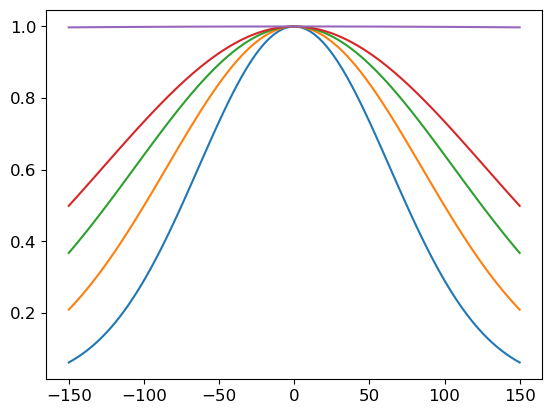

In [66]:
def understand_space_constant(lamtha):
    """Explore effect of space constant on spike raster."""
    x = np.linspace(-5, 5, 100)
    inplane_distance = 1  # example value
    return np.exp(-(x / (lamtha * inplane_distance)) ** 2)

x = np.linspace(-5, 5, 100)
plt.plot(x*30, understand_space_constant(3))
plt.plot(x*30, understand_space_constant(4))
plt.plot(x*30, understand_space_constant(5))

plt.plot(x*30, understand_space_constant(6))
plt.plot(x*30, understand_space_constant(100))

In [ ]:
from optimize_drives_slurm import set_params, set_params_time

with open('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/optim_time_scale_1000.pkl', 'rb') as f:
    optim = pickle.load(f)